# Pelatihan Model, Evaluasi Metrik MLM & Eksperimen Hyperparameter Tuning — BERT-from-Scratch (Kelompok 12)

**Identitas & Peran:**
- **Nama / Peran:** Bima (Anggota 3) — *Training Loop & Hyperparameter Tuning Engineer*
- **Metode Pengembangan:** *Vibe Coding* (kolaborasi bertahap, modular, transparan, dan mudah di-debug)
- **Target Hardware:** Google Colab (GPU NVIDIA T4 16GB)

---

### Ringkasan Optimasi untuk Menembus *Unigram Plateau* (`16.7%`)
1. **Arsitektur Pre-LN Transformer (`pre_norm=True`):** Menempatkan `LayerNorm` sebelum *Multi-Head Self-Attention* dan *Feed-Forward Network* ditambah `final_norm` di ujung encoder agar aliran gradien langsung mencapai *token & positional embeddings* sejak step pertama.
2. **Weight Tying (`tie_weights=True`):** Mengikat matriks `token_embeddings.weight` dengan `mlm_head.decoder.weight`.
3. **Jadwal Pelatihan Panjang (`batch_size=32`, `epochs=120`, `warmup_steps=1500`, `patience=15`):** Meningkatkan frekuensi update menjadi ~488 step/epoch (~58.500 total step maksimal) dengan *Cosine Annealing* (`min_lr_ratio=0.05`) dan *Early Stopping*.
4. **Evaluasi Top-1 & Top-5 MLM Accuracy:** Melacak akurasi Top-1 dan Top-5 hanya pada posisi token yang di-mask (`labels != -100`).

## Sel 1: Setup Google Drive & Reload Modul
Langsung me-*mount* Google Drive (`/content/drive/MyDrive/Bert-Kelompok12`) tanpa GitHub dan melakukan `importlib.reload` pada seluruh modul proyek.

In [10]:
import os
import sys
import copy
import json
import importlib
import torch
import matplotlib.pyplot as plt
from google.colab import drive

# 1. Mount Google Drive
drive.mount("/content/drive")

# 2. Arahkan ke folder proyek di Google Drive (sesuaikan jika berada di subfolder)
PROJECT_DIR = "/content/drive/MyDrive/Bert-Kelompok12"
os.chdir(PROJECT_DIR)
if PROJECT_DIR not in sys.path:
    sys.path.insert(0, PROJECT_DIR)

# 3. Reload modul yang sudah diperbarui agar perubahan langsung terbaca di sesi Colab
import data.data as data_mod
import model.model as model_mod
import training.utils as utils_mod
import training.train as train_mod

importlib.reload(data_mod)
importlib.reload(model_mod)
importlib.reload(utils_mod)
importlib.reload(train_mod)

from data.data import create_dataloaders
from model.model import BERT
from training.utils import load_config, set_seed
from training.train import train_model, evaluate

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
base_config = load_config("config.yaml")
print("Working Directory:", os.getcwd())
print("Device:", device)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Working Directory: /content/drive/MyDrive/Bert-Kelompok12
Device: cuda


## Sel 2: Eksperimen Hyperparameter Tuning Singkat (20 Epoch)
Membandingkan secara langsung efek **Post-LN vs Pre-LN**, **Learning Rate (`5e-4` vs `1e-3`)**, dan **Batch Size (`64` vs `32`)** untuk membuktikan konfigurasi mana yang berhasil menembus *unigram plateau* (`16.7%`).

In [11]:
TUNING_EPOCHS = 20

experiments = [
    {
        "name": "exp1_postln_lr5e4_bs64",
        "desc": "Post-LN | LR=5e-4 | BS=64 (Baseline Lama)",
        "pre_norm": False,
        "lr": 5e-4,
        "batch_size": 64,
        "warmup_steps": 400,
    },
    {
        "name": "exp2_preln_lr5e4_bs64",
        "desc": "Pre-LN  | LR=5e-4 | BS=64",
        "pre_norm": True,
        "lr": 5e-4,
        "batch_size": 64,
        "warmup_steps": 400,
    },
    {
        "name": "exp3_preln_lr1e3_bs64",
        "desc": "Pre-LN  | LR=1e-3 | BS=64",
        "pre_norm": True,
        "lr": 1e-3,
        "batch_size": 64,
        "warmup_steps": 400,
    },
    {
        "name": "exp4_preln_lr8e4_bs32",
        "desc": "Pre-LN  | LR=8e-4 | BS=32 (2x Steps/Epoch)",
        "pre_norm": True,
        "lr": 8e-4,
        "batch_size": 32,
        "warmup_steps": 800,
    },
]

tuning_results = {}

for exp in experiments:
    print("\n" + "=" * 80)
    print(f"MENJALANKAN: {exp['name']} ({exp['desc']})")
    print("=" * 80)

    cfg = copy.deepcopy(base_config)
    cfg["model"]["pre_norm"] = exp["pre_norm"]
    cfg["model"]["tie_weights"] = True
    cfg["training"]["epochs"] = TUNING_EPOCHS
    cfg["training"]["lr"] = exp["lr"]
    cfg["training"]["batch_size"] = exp["batch_size"]
    cfg["training"]["warmup_steps"] = exp["warmup_steps"]
    cfg["training"]["patience"] = None  # Matikan early stopping saat tuning 20 epoch

    set_seed(cfg["training"]["seed"])
    train_loader, val_loader, _ = create_dataloaders(cfg)
    model = BERT.from_config(cfg)

    hist = train_model(
        model=model,
        train_loader=train_loader,
        val_loader=val_loader,
        config=cfg,
        device=device,
        tag=exp["name"],
    )
    tuning_results[exp["name"]] = {
        "desc": exp["desc"],
        "history": hist,
        "best_val_acc": hist["best_val_acc"],
        "best_val_top5_acc": hist["best_val_top5_acc"],
        "best_val_ppl": hist["best_val_ppl"],
        "best_val_loss": hist["best_val_loss"],
    }

print("\n=== RINGKASAN HASIL TUNING (20 EPOCH) ===")
print(f"{'Eksperimen':<26} | {'Val Loss':<8} | {'Val PPL':<8} | {'Val Top-1':<10} | {'Val Top-5':<10}")
print("-" * 74)
for name, res in tuning_results.items():
    print(
        f"{name:<26} | {res['best_val_loss']:<8.4f} | {res['best_val_ppl']:<8.1f} | "
        f"{res['best_val_acc']*100:<9.2f}% | {res['best_val_top5_acc']*100:<9.2f}%"
    )


MENJALANKAN: exp1_postln_lr5e4_bs64 (Post-LN | LR=5e-4 | BS=64 (Baseline Lama))
=== Mulai Training _exp1_postln_lr5e4_bs64 | Device: cuda | Pre-LN: False | Epochs: 20 | Steps/Epoch: 244 | Total Steps: 4880 | Patience: None ===
Epoch 001/020 (3.4s) | LR: 3.05e-04 | Train Loss: 8.1693 Acc@1: 6.63% Acc@5: 18.90% | Val Loss: 6.8823 Acc@1: 8.97% Acc@5: 23.06% PPL: 974.8 * [BEST]
Epoch 002/020 (3.3s) | LR: 5.00e-04 | Train Loss: 6.8214 Acc@1: 10.34% Acc@5: 24.37% | Val Loss: 6.5535 Acc@1: 12.65% Acc@5: 27.18% PPL: 701.7 * [BEST]
Epoch 003/020 (3.3s) | LR: 4.94e-04 | Train Loss: 6.5829 Acc@1: 12.42% Acc@5: 26.47% | Val Loss: 6.3791 Acc@1: 14.12% Acc@5: 28.43% PPL: 589.4 * [BEST]
Epoch 004/020 (3.3s) | LR: 4.81e-04 | Train Loss: 6.4209 Acc@1: 13.57% Acc@5: 27.71% | Val Loss: 6.2619 Acc@1: 14.38% Acc@5: 29.31% PPL: 524.2 * [BEST]
Epoch 005/020 (3.3s) | LR: 4.62e-04 | Train Loss: 6.2998 Acc@1: 14.31% Acc@5: 28.43% | Val Loss: 6.2092 Acc@1: 15.36% Acc@5: 29.20% PPL: 497.3 * [BEST]
Epoch 006/020 

## Sel 3: Full Training Panjang (120 Epoch + Early Stopping)
Menjalankan pelatihan penuh pada konfigurasi terbaik (`pre_norm=True`, `batch_size=32`, `lr=8e-4`, `warmup_steps=1500`, `patience=15`) dan mengevaluasinya pada `test_loader`.

In [12]:
full_config = load_config("config.yaml")
set_seed(full_config["training"]["seed"])

train_loader, val_loader, test_loader = create_dataloaders(full_config)
best_model = BERT.from_config(full_config)

full_history = train_model(
    model=best_model,
    train_loader=train_loader,
    val_loader=val_loader,
    config=full_config,
    device=device,
    tag="full_preln_bs32",
)

# Evaluasi final pada Test Set menggunakan checkpoint terbaik
test_metrics = evaluate(
    model=best_model,
    dataloader=test_loader,
    device=device,
    use_amp=full_config["training"]["fp16"],
    ignore_index=full_config["data"]["ignore_index"],
)

print("\n" + "=" * 65)
print("HASIL AKHIR EVALUASI TEST SET (BEST CHECKPOINT)")
print("=" * 65)
print(f"Best Epoch       : {full_history['best_epoch']}")
print(f"Val  Loss / PPL  : {full_history['best_val_loss']:.4f} / {full_history['best_val_ppl']:.2f}")
print(f"Val  Top-1 / Top-5: {full_history['best_val_acc']*100:.2f}% / {full_history['best_val_top5_acc']*100:.2f}%")
print(f"Test Loss / PPL  : {test_metrics['loss']:.4f} / {test_metrics['ppl']:.2f}")
print(f"Test Top-1 / Top-5: {test_metrics['acc']*100:.2f}% / {test_metrics['top5_acc']*100:.2f}%")

=== Mulai Training _full_preln_bs32 | Device: cuda | Pre-LN: True | Epochs: 120 | Steps/Epoch: 487 | Total Steps: 58440 | Patience: 15 ===
Epoch 001/120 (4.4s) | LR: 2.60e-04 | Train Loss: 7.9011 Acc@1: 7.00% Acc@5: 19.66% | Val Loss: 6.8091 Acc@1: 10.13% Acc@5: 23.96% PPL: 906.0 * [BEST]
Epoch 002/120 (4.4s) | LR: 5.19e-04 | Train Loss: 6.7635 Acc@1: 10.85% Acc@5: 24.72% | Val Loss: 6.5055 Acc@1: 12.97% Acc@5: 27.79% PPL: 668.8 * [BEST]
Epoch 003/120 (4.4s) | LR: 7.79e-04 | Train Loss: 6.5293 Acc@1: 12.97% Acc@5: 26.97% | Val Loss: 6.3375 Acc@1: 14.66% Acc@5: 28.37% PPL: 565.4 * [BEST]
Epoch 004/120 (4.5s) | LR: 8.00e-04 | Train Loss: 6.3688 Acc@1: 14.12% Acc@5: 28.05% | Val Loss: 6.2342 Acc@1: 14.82% Acc@5: 28.98% PPL: 509.9 * [BEST]
Epoch 005/120 (4.4s) | LR: 7.99e-04 | Train Loss: 6.2522 Acc@1: 14.68% Acc@5: 28.60% | Val Loss: 6.2251 Acc@1: 15.47% Acc@5: 28.93% PPL: 505.3 * [BEST]
Epoch 006/120 (4.4s) | LR: 7.99e-04 | Train Loss: 6.1817 Acc@1: 14.74% Acc@5: 28.66% | Val Loss: 6.100

## Sel 4: Plot Kurva Loss, Perplexity, serta Top-1 & Top-5 Accuracy

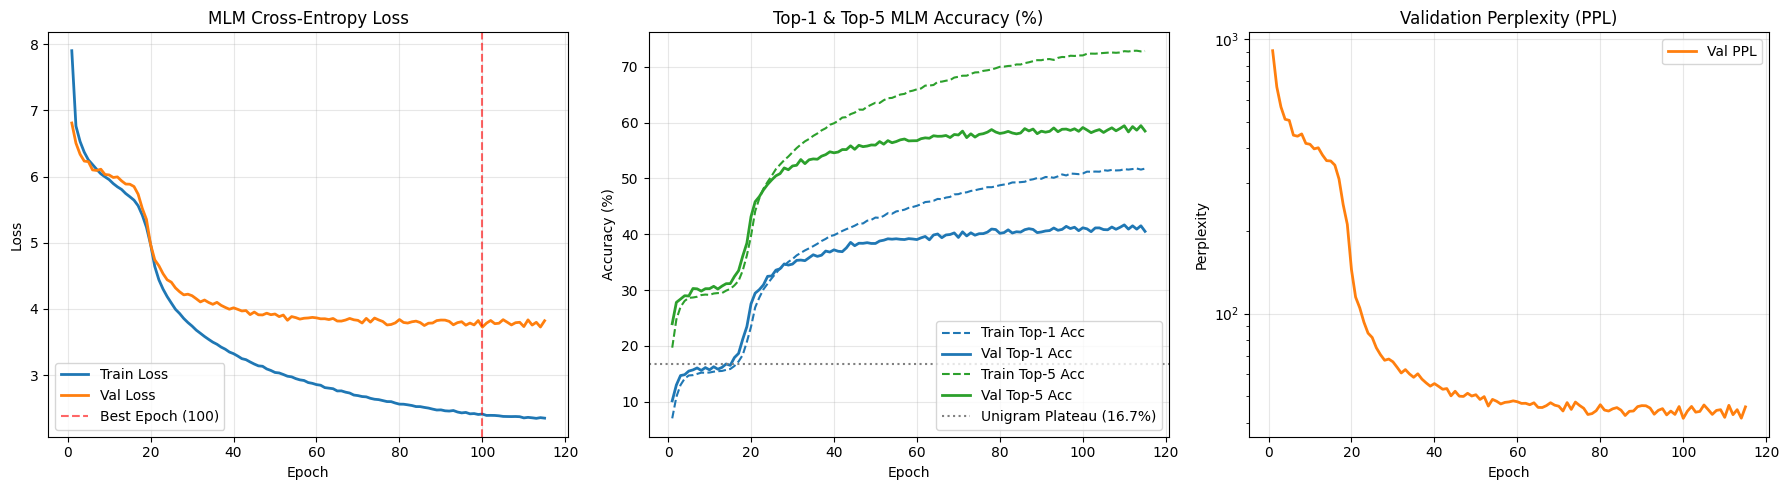

In [13]:
epochs_ran = range(1, len(full_history["train_loss"]) + 1)

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# 1. Plot Loss
axes[0].plot(epochs_ran, full_history["train_loss"], label="Train Loss", lw=2)
axes[0].plot(epochs_ran, full_history["val_loss"], label="Val Loss", lw=2)
axes[0].axvline(full_history["best_epoch"], color="red", linestyle="--", alpha=0.6, label=f"Best Epoch ({full_history['best_epoch']})")
axes[0].set_title("MLM Cross-Entropy Loss")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")
axes[0].legend()
axes[0].grid(True, alpha=0.3)

# 2. Plot Top-1 & Top-5 Accuracy
axes[1].plot(epochs_ran, [a * 100 for a in full_history["train_acc"]], label="Train Top-1 Acc", linestyle="--", color="tab:blue")
axes[1].plot(epochs_ran, [a * 100 for a in full_history["val_acc"]], label="Val Top-1 Acc", lw=2, color="tab:blue")
axes[1].plot(epochs_ran, [a * 100 for a in full_history["train_top5_acc"]], label="Train Top-5 Acc", linestyle="--", color="tab:green")
axes[1].plot(epochs_ran, [a * 100 for a in full_history["val_top5_acc"]], label="Val Top-5 Acc", lw=2, color="tab:green")
axes[1].axhline(16.7, color="gray", linestyle=":", label="Unigram Plateau (16.7%)")
axes[1].set_title("Top-1 & Top-5 MLM Accuracy (%)")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy (%)")
axes[1].legend()
axes[1].grid(True, alpha=0.3)

# 3. Plot Validation Perplexity
axes[2].plot(epochs_ran, full_history["val_ppl"], label="Val PPL", color="tab:orange", lw=2)
axes[2].set_title("Validation Perplexity (PPL)")
axes[2].set_xlabel("Epoch")
axes[2].set_ylabel("Perplexity")
axes[2].set_yscale("log")
axes[2].legend()
axes[2].grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig("checkpoints/training_curves_top1_top5.png", dpi=150)
plt.show()

## Sel 5: Uji Inferensi Kontekstual `[MASK]` (Bukti Keluar dari Unigram Plateau)

In [14]:
with open(full_config["data"]["vocab_path"], "r", encoding="utf-8") as f:
    vocab_data = json.load(f)

# Dukung struktur vocab.json baik langsung dict {token: id} maupun {"token_to_id": ...}
token2id = vocab_data.get("token_to_id", vocab_data.get("stoi", vocab_data))
id2token = {int(v): k for k, v in token2id.items()}

PAD_ID = full_config["data"]["pad_token_id"]
UNK_ID = full_config["data"]["unk_token_id"]
CLS_ID = full_config["data"]["cls_token_id"]
SEP_ID = full_config["data"]["sep_token_id"]
MASK_ID = full_config["data"]["mask_token_id"]
MAX_LEN = full_config["data"]["max_seq_len"]


@torch.no_grad()
def predict_masked_sentence(sentence: str, model: torch.nn.Module, top_k: int = 5):
    model.eval()
    tokens = sentence.strip().split()
    input_ids = [CLS_ID]
    mask_positions = []

    for tok in tokens:
        if tok == "[MASK]":
            mask_positions.append(len(input_ids))
            input_ids.append(MASK_ID)
        else:
            input_ids.append(token2id.get(tok.lower(), token2id.get(tok, UNK_ID)))

    input_ids.append(SEP_ID)
    seq_len = len(input_ids)
    attention_mask = [1] * seq_len

    # Pad ke MAX_LEN (128) sesuai kontrak SPEC.md
    pad_len = MAX_LEN - seq_len
    input_ids += [PAD_ID] * pad_len
    attention_mask += [0] * pad_len
    token_type_ids = [0] * MAX_LEN

    inp_t = torch.tensor([input_ids], dtype=torch.long, device=device)
    mask_t = torch.tensor([attention_mask], dtype=torch.long, device=device)
    type_t = torch.tensor([token_type_ids], dtype=torch.long, device=device)

    outputs = model(input_ids=inp_t, attention_mask=mask_t, token_type_ids=type_t)
    logits = outputs["logits"][0]  # (128, V)

    print(f"\nKalimat Uji : {sentence}")
    for pos in mask_positions:
        probs = torch.softmax(logits[pos], dim=-1)
        top_probs, top_idxs = torch.topk(probs, k=top_k)
        preds_str = ", ".join(
            [f"'{id2token.get(idx.item(), '<unk>')}' ({p.item()*100:.1f}%)" for p, idx in zip(top_probs, top_idxs)]
        )
        print(f"  -> Top-{top_k} Prediksi [MASK]: {preds_str}")


test_sentences = [
    "the album was released [MASK] 2005 by the record label .",
    "he played as a [MASK] for the national football team .",
    "she was born in london , [MASK] and studied music .",
    "during the second world [MASK] , the city was heavily damaged .",
    "the film directed [MASK] steven spielberg won several awards .",
]

for s in test_sentences:
    predict_masked_sentence(s, best_model, top_k=5)


Kalimat Uji : the album was released [MASK] 2005 by the record label .
  -> Top-5 Prediksi [MASK]: 'in' (98.9%), 'by' (0.4%), 'from' (0.2%), 'until' (0.2%), 'for' (0.1%)

Kalimat Uji : he played as a [MASK] for the national football team .
  -> Top-5 Prediksi [MASK]: 'coach' (24.0%), 'member' (4.8%), 'player' (4.2%), 'manager' (3.5%), 'representative' (3.1%)

Kalimat Uji : she was born in london , [MASK] and studied music .
  -> Top-5 Prediksi [MASK]: 'england' (13.8%), 'london' (11.4%), 'norwood' (10.7%), 'virginia' (6.3%), 'italy' (4.2%)

Kalimat Uji : during the second world [MASK] , the city was heavily damaged .
  -> Top-5 Prediksi [MASK]: 'war' (95.6%), 'i' (1.7%), 'ii' (0.8%), 'uprising' (0.3%), 'campaign' (0.2%)

Kalimat Uji : the film directed [MASK] steven spielberg won several awards .
  -> Top-5 Prediksi [MASK]: 'by' (85.0%), '.' (7.2%), 'and' (4.2%), ';' (0.8%), ',' (0.5%)
